# VALORA AI — Exploratory Data Analysis (EDA)
**Project:** Apartment asking-price estimation in Montenegro  
**Notebook:** 01_EDA — follows the professor’s 13-section draft.


## 1. TL;DR
This notebook explores apartment asking prices in Montenegro. I clean the online listings, check the quality of the data, and study how prices relate to size and location. The exact results will be shown after running the notebook.


## 2. Introduction & motivation
My project, Valora AI, aims to estimate apartment asking prices in Montenegro. I want to understand which property characteristics may be useful for a machine learning model. This analysis focuses on apartments and is not a study of confirmed sale prices.


## 3. Data provenance
The input is `VALORA_AI_FINAL_COLAB.csv`, compiled from online property listings, professional appraisals, and synthetic records. For this apartment EDA, I use **non-synthetic online apartment listings only**. The source file does not by itself establish the collection dates, publication rights, or permission to redistribute the data; these should be documented separately before publishing the dataset. The raw CSV remains unchanged.


## 4. Data dictionary
The main fields are:

| Column | Meaning | Units / values |
|---|---|---|
| `price_eur` | Advertised asking price | EUR |
| `area_m2` | Apartment area | m² |
| `bedrooms` | Number of bedrooms | count |
| `city` | City or municipality | text |
| `location` | More detailed location | text |
| `property_type` | Type of property | text |
| `data_source` | Origin of the record | category |
| `is_synthetic` | Whether the record is generated | Boolean |
| `listing_id`, `source` | Listing identifiers | text |
| `price_per_m2` | Asking price divided by area (created during cleaning) | EUR/m² |


## 5. Setup
I import the libraries and load the CSV. In VS Code, I first look in `data/raw/` relative to the project folder. If the file is not there, I can select it in Google Colab. This keeps the original dataset unchanged.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

raw_path = Path('data/raw/VALORA_AI_FINAL_COLAB.csv')
if not raw_path.exists():
    raw_path = Path('VALORA_AI_FINAL_COLAB.csv')
if not raw_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        raw_path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Put VALORA_AI_FINAL_COLAB.csv in data/raw/ or the project folder.')
df = pd.read_csv(raw_path, low_memory=False)
df = df.rename(columns={'izvor':'source', 'sobe':'bedrooms', 'kupatila':'bathrooms',
                        'lokacija':'location', 'naslov':'title', 'opis':'description',
                        'provjera':'verification'})
print('Dataset shape:', df.shape)


Saving VALORA_AI_FINAL_COLAB.csv to VALORA_AI_FINAL_COLAB.csv
Dataset shape: (6913, 59)


## 6. First look
I inspect the first rows, column types, and source categories. This helps me understand the available information before cleaning.


In [2]:
display(df.head())
df.info()
print('\nData sources:')
print(df['data_source'].value_counts(dropna=False))
print('\nProperty types:')
print(df['property_type'].value_counts(dropna=False).head(12))


,listing_id,source,property_type,price_eur,area_m2,cijena_po_m2,bedrooms,bathrooms,location,city,...,Land_Area_m2,Bedrooms,Floor,Condition,Year_Built,Price_per_m2_EUR,Data_Source,is_synthetic,price_per_m2_calculated,has_price_and_area
0,2778761,Realitica,kuća,650000.0,250.0,2600.00,NaN,NaN,"Bar, Bar,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2600.000000,True
1,2961851,Realitica,kuća,520000.0,95.0,5473.68,NaN,NaN,"Baošići,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,5473.684211,True
2,3000522,Realitica,kuća,580000.0,314.0,1847.13,NaN,NaN,"Bijela,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,1847.133758,True
3,3000970,Realitica,kuća,580000.0,285.0,2035.09,NaN,NaN,"Đenovići,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2035.087719,True
4,3001059,Realitica,kuća,320000.0,149.0,2147.65,NaN,NaN,"Podi,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2147.651007,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6913 entries, 0 to 6912
Data columns (total 59 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   listing_id                  5986 non-null   object 
 1   source                      3986 non-null   object 
 2   property_type               6911 non-null   object 
 3   price_eur                   6401 non-null   float64
 4   area_m2                     6129 non-null   float64
 5   cijena_po_m2                3986 non-null   float64
 6   bedrooms                    3454 non-null   float64
 7   bathrooms                   386 non-null    float64
 8   location                    3986 non-null   object 
 9   city                        6825 non-null   object 
 10  title                       3986 non-null   object 
 11  url                         1986 non-null   object 
 12  description                 549 non-null    object 
 13  verification                3986 

## 7. Data quality audit
I check missing values and duplicates. Then I select real apartment listings and remove records outside simple price, area, and price-per-square-meter limits. I also standardize city names and use the location text only when a municipality can be identified. The limits are practical cleaning rules, not proof that excluded listings are incorrect.


In [3]:
print('Missing values in key fields:')
display(df[['price_eur','area_m2','city','property_type']].isna().sum())
print('Exact duplicate rows:', df.duplicated().sum())


Missing values in key fields:


,0
price_eur,512
area_m2,784
city,88
property_type,2


Exact duplicate rows: 0


In [4]:
work = df.copy()
work['property_type_clean'] = work['property_type'].astype('string').str.strip().str.lower()
work['price_eur'] = pd.to_numeric(work['price_eur'], errors='coerce')
work['area_m2'] = pd.to_numeric(work['area_m2'], errors='coerce')
work['bedrooms'] = pd.to_numeric(work['bedrooms'], errors='coerce')

real = work[(work['data_source'] == 'Online listing') &
            (work['is_synthetic'] == False) &
            (work['property_type_clean'].isin(['stan', 'apartment']))].copy()
print('Real apartment listings before cleaning:', len(real))
real = real.drop_duplicates(subset=['source', 'listing_id'])
real = real[real['price_eur'].between(10000, 2000000) & real['area_m2'].between(15, 350)].copy()
real['price_per_m2'] = real['price_eur'] / real['area_m2']
real = real[real['price_per_m2'].between(300, 15000)].copy()
print('Real apartment listings after cleaning:', len(real))
# Correct city labels using the location information when possible.
# Keep the original values for checking later.
real['city_original'] = real['city']
valid_cities = ['Podgorica','Budva','Bar','Kotor','Tivat','Herceg Novi','Ulcinj',
                'Nikšić','Cetinje','Kolašin','Žabljak','Bijelo Polje','Berane',
                'Danilovgrad','Pljevlja','Plav','Rožaje','Mojkovac','Petnjica',
                'Tuzi','Zeta','Andrijevica','Šavnik','Plužine','Gusinje']
aliases = {'Niksic':'Nikšić','Kolasin':'Kolašin','Zabljak':'Žabljak',
           'Rozaje':'Rožaje','Savnik':'Šavnik','Pluzine':'Plužine'}
# Some coastal settlements belong to larger municipalities.
settlements = {'Đenovići':'Herceg Novi', 'Djenovici':'Herceg Novi',
               'Meljine':'Herceg Novi', 'Baošići':'Herceg Novi',
               'Baosici':'Herceg Novi', 'Dobrota':'Kotor',
               'Bečići':'Budva', 'Becici':'Budva', 'Rafailovići':'Budva',
               'Rafailovici':'Budva'}
real['city'] = real['city'].astype('string').str.strip().replace(aliases)
real['city'] = real['city'].where(real['city'].isin(valid_cities))
location_text = real['location'].fillna('').astype(str)
for name, city_name in {**dict.fromkeys(valid_cities), **aliases, **settlements}.items():
    target = city_name if city_name is not None else name
    matches = real['city'].isna() & location_text.str.contains(
        r'(?<!\w)' + re.escape(name) + r'(?!\w)', case=False, regex=True)
    real.loc[matches, 'city'] = target
real['city'] = real['city'].fillna('Unknown')
print('City values still unknown:', (real['city'] == 'Unknown').sum())
display(real[['city', 'location', 'area_m2', 'bedrooms', 'price_eur', 'price_per_m2']].head())


Real apartment listings before cleaning: 2473
Real apartment listings after cleaning: 2432
City values still unknown: 186


,city,location,area_m2,bedrooms,price_eur,price_per_m2
95,Herceg Novi,"Đenovići,",59.0,1.0,154000.0,2610.169492
96,Herceg Novi,"Meljine,",230.0,5.0,1520000.0,6608.695652
97,Kotor,"Kotor, Kotor,",58.0,1.0,320000.0,5517.241379
98,Herceg Novi,"Baošići,",93.0,2.0,220000.0,2365.591398
99,Herceg Novi,"Herceg Novi,",178.0,3.0,550000.0,3089.887640


The cleaned `city` field should contain municipality names or `Unknown`. I keep the original city value in `city_original` for auditing. Unknown values are not guessed. The cleaning results above show how many apartments remain.


## 8. Univariate exploration
I look at each important variable separately. Histograms show the distribution of asking prices and apartment areas. A bedroom-count chart and a city-count chart help me understand the composition of the listings.


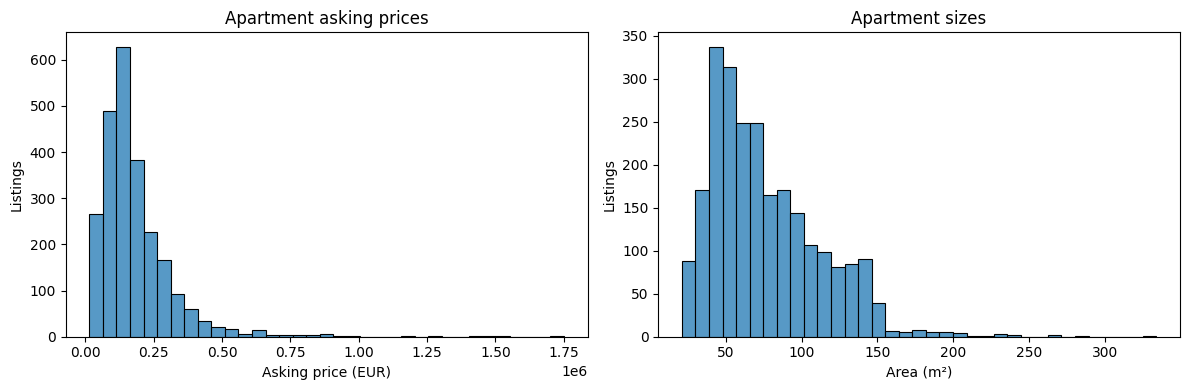

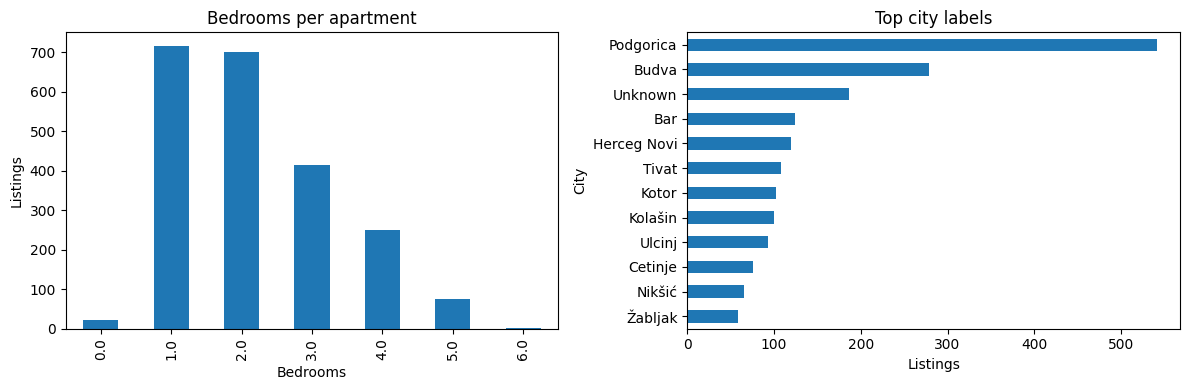

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(real['price_eur'], bins=35, ax=axes[0])
axes[0].set(title='Apartment asking prices', xlabel='Asking price (EUR)', ylabel='Listings')
sns.histplot(real['area_m2'], bins=35, ax=axes[1])
axes[1].set(title='Apartment sizes', xlabel='Area (m²)', ylabel='Listings')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
real['bedrooms'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set(title='Bedrooms per apartment', xlabel='Bedrooms', ylabel='Listings')
real['city'].value_counts().head(12).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set(title='Top city labels', xlabel='Listings', ylabel='City')
plt.tight_layout()
plt.show()


The charts show which price ranges, apartment sizes, and cities appear most often in the cleaned dataset. I will interpret the actual patterns after running the notebook.


## 9. Bivariate exploration
I compare apartment area with asking price, median price per square meter across cities, and numeric correlations. The **heatmap** summarizes correlations between numeric variables. These relationships do not prove causation.


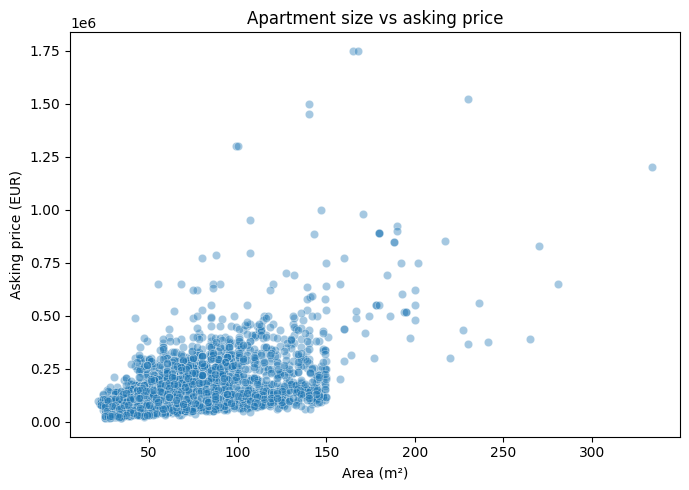

,listings,median_eur_m2
city,,
Tivat,108,3887.397465
Kotor,102,3447.198276
Budva,279,3400.000000
Herceg Novi,119,3071.428571
Podgorica,541,2777.777778
Bar,124,2564.738292
Kolašin,100,2403.535980
Ulcinj,93,2098.765432
Žabljak,58,2064.988334


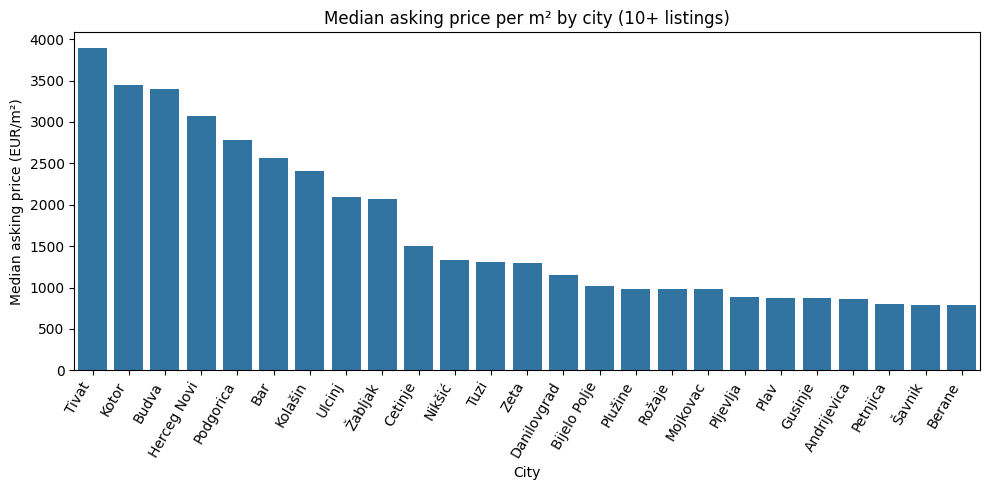

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=real, x='area_m2', y='price_eur', alpha=0.4)
plt.title('Apartment size vs asking price')
plt.xlabel('Area (m²)')
plt.ylabel('Asking price (EUR)')
plt.tight_layout()
plt.show()

city_stats = (real[real['city'] != 'Unknown']
              .groupby('city')
              .agg(listings=('price_eur','size'), median_eur_m2=('price_per_m2','median'))
              .query('listings >= 10')
              .sort_values('median_eur_m2', ascending=False))
display(city_stats)
plt.figure(figsize=(10, 5))
sns.barplot(x=city_stats.index, y=city_stats['median_eur_m2'])
plt.title('Median asking price per m² by city (10+ listings)')
plt.xlabel('City')
plt.ylabel('Median asking price (EUR/m²)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()


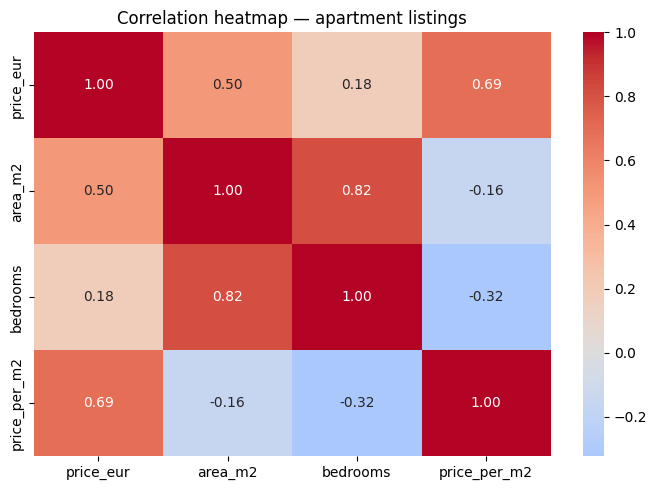

In [7]:
numeric_cols = ['price_eur', 'area_m2', 'bedrooms', 'price_per_m2']
plt.figure(figsize=(7, 5))
sns.heatmap(real[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation heatmap — apartment listings')
plt.tight_layout()
plt.show()


The heatmap shows correlations from -1 to 1. `price_per_m2` is useful for EDA but must **not** be an input when predicting `price_eur`, because it is calculated using the target price.


## 10. Key findings
After running the notebook, I will report the final number of cleaned apartments, the most common cities, the median asking price, and the relationship between size and price. These are listing-based findings, not confirmed sale-price conclusions.


In [8]:
print('Cleaned apartments:', len(real))
print('Unknown city labels:', (real['city'] == 'Unknown').sum())
print('Median asking price (EUR):', round(real['price_eur'].median(), 2))
print('Median asking price per m² (EUR):', round(real['price_per_m2'].median(), 2))
print('Correlation between area and asking price:', round(real['area_m2'].corr(real['price_eur']), 3))


Cleaned apartments: 2432
Unknown city labels: 186
Median asking price (EUR): 148000.0
Median asking price per m² (EUR): 2480.96
Correlation between area and asking price: 0.504


## 11. Decisions carried forward
For modelling, I will use apartment area, bedrooms, and the cleaned city label. I will also test **Feature Engineering**, including `area_squared`, `size_group`, and `area_per_bedroom`, to see whether these improve predictions. The target will be `price_eur`. I will keep price-derived variables out of the model inputs to avoid data leakage.


## 12. Export
I save the cleaned apartment dataset to `data/processed/` so the modelling notebook can use the same records. The original CSV is not modified.


In [9]:
processed_dir = Path('data/processed')
processed_dir.mkdir(parents=True, exist_ok=True)
output_path = processed_dir / 'valora_apartments_clean.csv'
real.to_csv(output_path, index=False)
print('Saved cleaned dataset:', output_path.resolve())
print('Rows exported:', len(real))


Saved cleaned dataset: /content/data/processed/valora_apartments_clean.csv
Rows exported: 2432


## 13. Appendix
**Limitations:** Online asking prices may differ from actual transaction prices. Some city labels remain unknown. Cleaning thresholds can remove valid unusual properties. I will use held-out data and model evaluation in `02_Modelling.ipynb` to check prediction quality.
